# Coffee sales 2025: analysis in Python
Data: `coffee_sales_2025.csv` (one row per order).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("coffee_sales_2025.csv", parse_dates=["date"])
df.head()

,order_id,date,branch,product,category,quantity,unit_price,customer_type,payment,sales
0,10001,2025-01-01,Maadi,Iced Latte,Cold drinks,1,80,Member,Cash,80
1,10002,2025-01-01,Maadi,Iced Latte,Cold drinks,1,80,Guest,Cash,80
2,10003,2025-01-01,Maadi,Green Tea,Tea,1,35,Member,Cash,35
3,10004,2025-01-01,Maadi,Cappuccino,Coffee,2,70,Guest,Wallet,140
4,10005,2025-01-01,Maadi,Lemon Mint,Cold drinks,1,55,Member,Wallet,55


In [2]:
df.shape

(20838, 10)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20838 entries, 0 to 20837
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       20838 non-null  int64         
 1   date           20838 non-null  datetime64[us]
 2   branch         20838 non-null  str           
 3   product        20838 non-null  str           
 4   category       20838 non-null  str           
 5   quantity       20838 non-null  int64         
 6   unit_price     20838 non-null  int64         
 7   customer_type  20838 non-null  str           
 8   payment        20838 non-null  str           
 9   sales          20838 non-null  int64         
dtypes: datetime64[us](1), int64(4), str(5)
memory usage: 1.6 MB


In [4]:
df.describe()

,order_id,date,quantity,unit_price,sales
count,20838.000000,20838,20838.000000,20838.000000,20838.000000
mean,20419.500000,2025-07-06 17:01:26.035128,1.431231,65.245273,93.550149
min,10001.000000,2025-01-01 00:00:00,1.000000,30.000000,30.000000
25%,15210.250000,2025-04-16 00:00:00,1.000000,45.000000,55.000000
50%,20419.500000,2025-07-09 00:00:00,1.000000,70.000000,77.000000
75%,25628.750000,2025-09-27 00:00:00,2.000000,82.000000,100.000000
max,30838.000000,2025-12-31 00:00:00,4.000000,105.000000,420.000000
std,6015.556791,NaN,0.753898,20.559811,59.936388


In [5]:
# The messy copy: extra spaces, MIXED case, blanks, duplicates, two date styles
messy = pd.read_csv("coffee_sales_messy.csv")
messy["branch"].value_counts()

branch
Zamalek          435
Maadi            368
Nasr City        329
Heliopolis       285
  nasr city       19
ZAMALEK           18
  maadi           17
  zamalek         17
MAADI             16
  heliopolis      11
NASR CITY          9
HELIOPOLIS         6
Name: count, dtype: int64

In [6]:
clean = messy.copy()
clean["branch"] = clean["branch"].str.strip().str.title()
clean["product"] = clean["product"].str.strip()
clean["date"] = pd.to_datetime(clean["date"], format="mixed", dayfirst=True)
clean["payment"] = clean["payment"].fillna("Unknown")
print("duplicates:", clean.duplicated().sum())
clean = clean.drop_duplicates()
clean["branch"].value_counts()

duplicates: 30


branch
Zamalek       464
Maadi         393
Nasr City     349
Heliopolis    294
Name: count, dtype: int64

In [7]:
by_branch = (df.groupby("branch")
               .agg(sales=("sales", "sum"), orders=("order_id", "count"), avg_order=("sales", "mean"))
               .sort_values("sales", ascending=False))
by_branch.round(1)

,sales,orders,avg_order
branch,,,
Zamalek,584642,6207,94.2
Maadi,522355,5586,93.5
Nasr City,454465,4837,94.0
Heliopolis,387936,4208,92.2


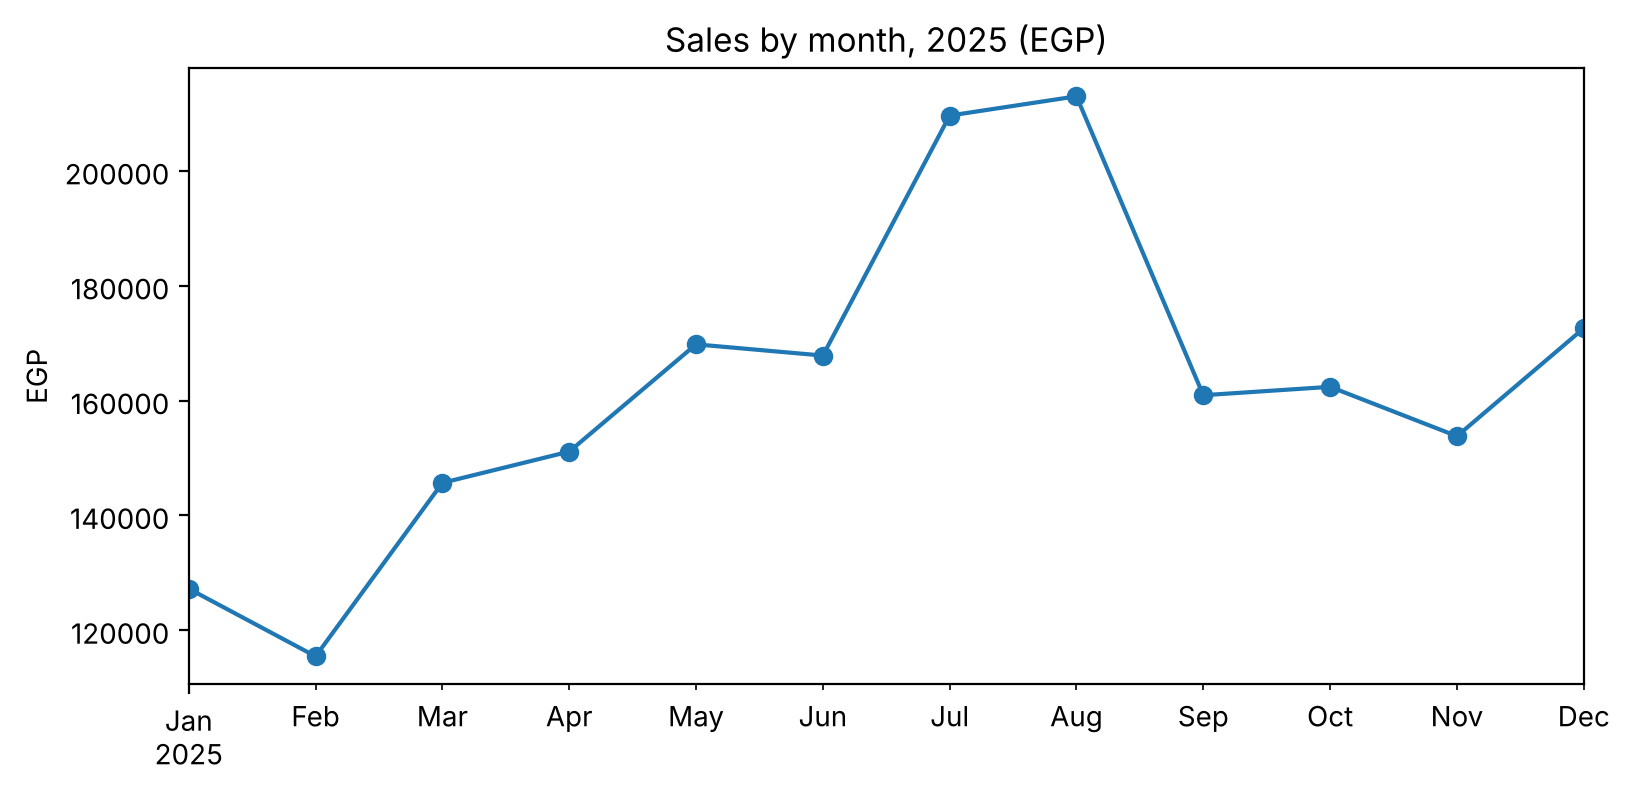

In [8]:
monthly = df.groupby(df["date"].dt.to_period("M"))["sales"].sum()
ax = monthly.plot(marker="o", figsize=(9, 4), title="Sales by month, 2025 (EGP)")
ax.set_xlabel("")
ax.set_ylabel("EGP")
plt.show()

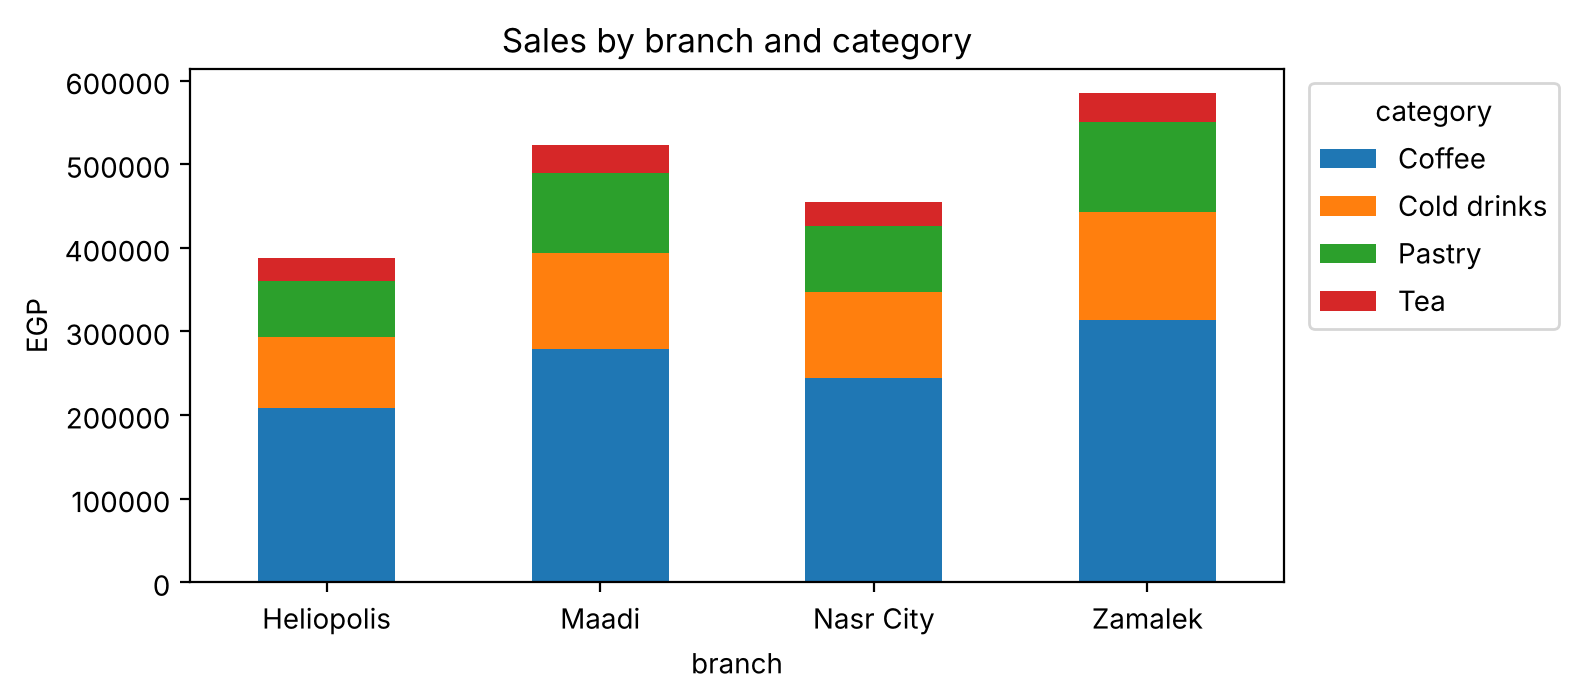

In [9]:
table = df.pivot_table(index="branch", columns="category", values="sales", aggfunc="sum")
table.plot(kind="bar", stacked=True, figsize=(8, 3.6), title="Sales by branch and category", rot=0)
plt.ylabel("EGP")
plt.legend(title="category", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [10]:
targets = pd.read_csv("branch_targets.csv")
report = by_branch.reset_index().merge(targets, on="branch")
report["monthly_avg"] = report["sales"] / 12
report["status"] = report.apply(lambda r: "On target" if r.monthly_avg >= r.monthly_target_egp else "Below target", axis=1)
report.round(0)

,branch,sales,orders,avg_order,monthly_target_egp,monthly_avg,status
0,Zamalek,584642,6207,94.0,50000,48720.0,Below target
1,Maadi,522355,5586,94.0,42000,43530.0,On target
2,Nasr City,454465,4837,94.0,36000,37872.0,On target
3,Heliopolis,387936,4208,92.0,35000,32328.0,Below target


In [11]:
report.to_excel("branch_report.xlsx", index=False)
print("Saved branch_report.xlsx")

Saved branch_report.xlsx
